# 05 — Retention & Cohort Analysis

Measure customer retention by acquisition cohort and connect retention to business outcomes.


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

TX = ROOT / "data" / "processed" / "transactions.csv"
CF = ROOT / "data" / "processed" / "customer_features.csv"

df = pd.read_csv(TX, parse_dates=["InvoiceDate"])
customers = pd.read_csv(CF)


## Build acquisition cohorts

In [2]:

df["order_month"] = df["InvoiceDate"].dt.to_period("M")

cohort_month = (
    df.groupby("CustomerID")["order_month"]
      .min()
      .rename("cohort_month")
)

df = df.join(cohort_month, on="CustomerID")

df["cohort_index"] = (
    df["order_month"].astype("int64")
    - df["cohort_month"].astype("int64")
)

display(df[["CustomerID","order_month","cohort_month","cohort_index"]].head())


,CustomerID,order_month,cohort_month,cohort_index
0,13085,2009-12,2009-12,0
1,13085,2009-12,2009-12,0
2,13085,2009-12,2009-12,0
3,13085,2009-12,2009-12,0
4,13085,2009-12,2009-12,0


## Customer retention matrix

In [3]:

cohort_counts = (
    df.groupby(["cohort_month","cohort_index"])["CustomerID"]
      .nunique()
      .reset_index()
)

retention = cohort_counts.pivot(
    index="cohort_month",
    columns="cohort_index",
    values="CustomerID"
)

retention_pct = retention.div(
    retention.iloc[:,0],
    axis=0
) * 100

display(retention_pct.round(1))


cohort_index,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
cohort_month,,,,,,,,,,,,,,,,,,,,,
2009-12,100.0,35.3,33.4,42.5,38.0,35.9,37.7,34.2,33.6,36.2,...,30.3,26.3,30.3,28.3,26.0,25.5,31.5,30.5,40.7,19.7
2010-01,100.0,20.6,31.1,30.5,26.4,30.0,25.8,23.0,27.9,31.9,...,15.1,23.5,19.8,18.5,19.6,24.3,19.3,24.5,5.7,NaN
2010-02,100.0,23.8,22.5,29.1,24.6,20.1,19.3,28.6,25.4,27.5,...,20.1,16.0,16.3,14.4,23.0,23.0,16.3,5.9,NaN,NaN
2010-03,100.0,19.0,23.0,24.2,23.3,20.3,24.6,30.2,27.5,10.8,...,16.9,17.4,15.6,17.6,20.1,21.2,7.9,NaN,NaN,NaN
2010-04,100.0,19.4,19.4,16.3,18.4,22.4,27.6,26.2,10.5,10.9,...,15.6,13.9,15.0,18.0,22.4,5.8,NaN,NaN,NaN,NaN
2010-05,100.0,15.7,16.9,17.3,17.7,25.6,21.3,12.6,5.9,8.3,...,12.6,13.8,16.5,15.4,4.7,NaN,NaN,NaN,NaN,NaN
2010-06,100.0,17.4,18.9,20.4,23.0,28.5,12.6,8.9,8.1,11.9,...,12.2,13.3,20.4,5.2,NaN,NaN,NaN,NaN,NaN,NaN
2010-07,100.0,15.6,18.3,29.6,29.0,14.0,11.3,14.5,14.5,11.3,...,17.2,23.7,8.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-08,100.0,20.4,29.6,32.1,17.3,11.7,9.9,12.3,13.6,13.0,...,19.8,6.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


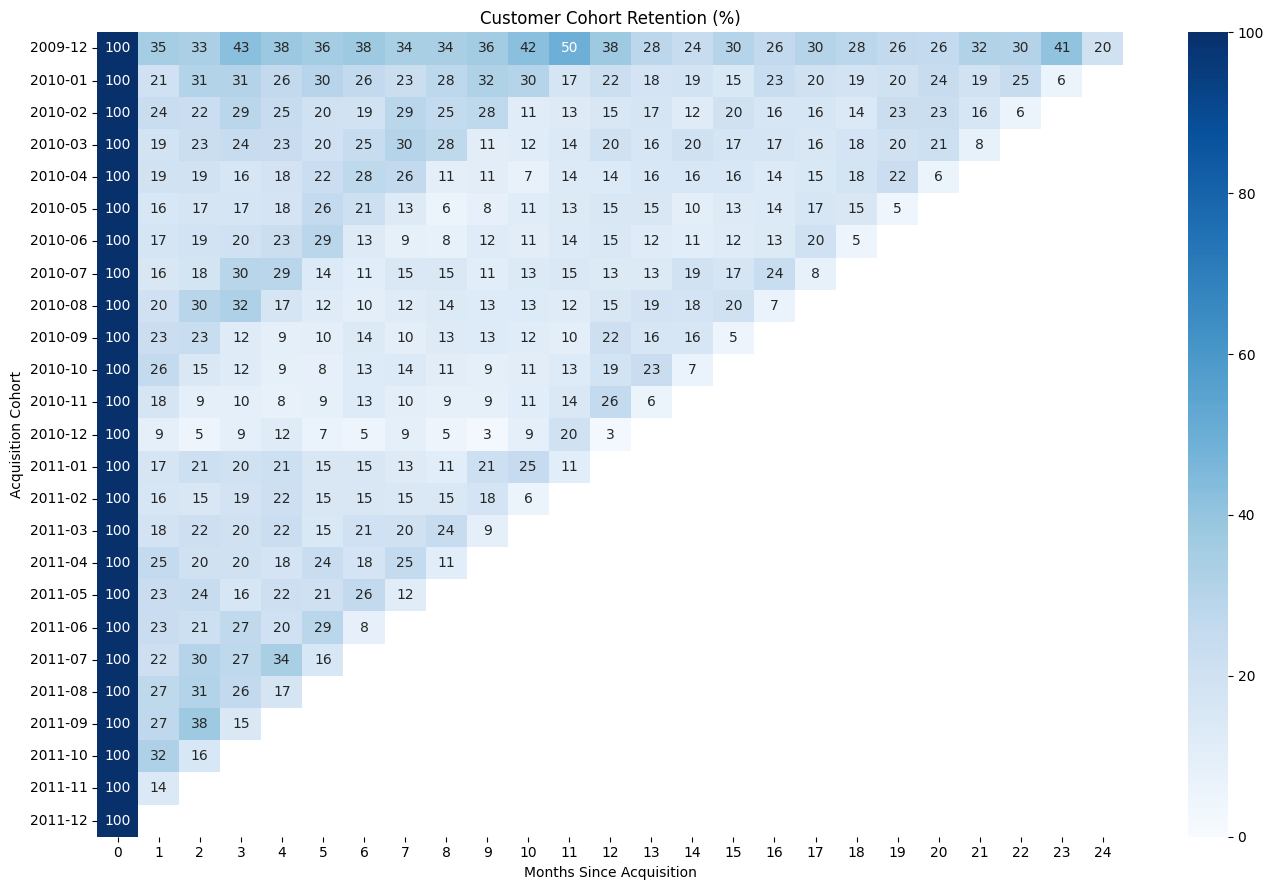

In [4]:

plt.figure(figsize=(14,9))
sns.heatmap(
    retention_pct,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    vmin=0,
    vmax=100
)
plt.title("Customer Cohort Retention (%)")
plt.xlabel("Months Since Acquisition")
plt.ylabel("Acquisition Cohort")
plt.tight_layout()
plt.show()


## Repeat-purchase rate

In [5]:

frequency = df.groupby("CustomerID")["InvoiceNo"].nunique()
repeat_purchase_rate = (frequency > 1).mean()

print(f"Repeat purchase rate: {repeat_purchase_rate:.2%}")


Repeat purchase rate: 72.39%


## Churn rate and revenue at risk

In [6]:

if "churn" in customers.columns:
    print(f"Churn rate: {customers['churn'].mean():.2%}")
else:
    print("No churn label in customer_features.csv; see notebook 04.")


No churn label in customer_features.csv; see notebook 04.


In [7]:

if {"churn_probability","churn_risk"}.issubset(customers.columns):
    high_risk = customers["churn_risk"].eq("HIGH")
    revenue_at_risk = customers.loc[high_risk, "monetary"].sum()

    print("High-risk customers:", int(high_risk.sum()))
    print("Revenue at risk:", round(revenue_at_risk, 2))
else:
    print("Join model predictions to customer_features.csv to calculate revenue at risk.")


Join model predictions to customer_features.csv to calculate revenue at risk.


## Retention by segment

If the segmentation notebook has produced a `segment` column, merge it into the transaction data and compare customer activity across segments.

Recommended questions:

- Which segment retains best?
- Which segment loses customers fastest?
- Which segment has the highest revenue at risk?
- Should retention spending be concentrated on high-value/high-risk customers?


In [8]:

if "segment" in customers.columns:
    segment_map = customers[["CustomerID","segment"]]
    segment_tx = df.merge(segment_map, on="CustomerID", how="left")

    segment_monthly = (
        segment_tx.groupby(["segment","order_month"])["CustomerID"]
                  .nunique()
                  .reset_index(name="active_customers")
    )

    display(segment_monthly.head(30))
else:
    print("Run segmentation first to analyze retention by segment.")


Run segmentation first to analyze retention by segment.


## Business recommendations

Use the actual results to formulate recommendations such as:

- High-value/high-risk → VIP retention campaign
- Low-frequency customers → second-purchase campaign
- New customers with weak repeat behavior → onboarding campaign
- Loyal customers → loyalty rewards
- Weak cohorts → investigate acquisition quality, pricing or product fit

The recommendations should be evidence-based rather than generic.
